In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
def preparer_donnees_rte(chemin_fichier):
    
    # Chargement des données
    df = pd.read_csv(chemin_fichier)
    col_date = 'date_heure_utc'
    
    # Conversion en datetime et on indexe (On reste en UTC pour s'aligner avec la Météo)
    df[col_date] = pd.to_datetime(df[col_date], utc=True)
    df = df.set_index(col_date)
    df = df.sort_index()
    
    # 1. Harmonisation temporelle : moyenne par heure pleine
    df = df.resample('h').mean()
    
    # 2. Harmonisation physique : on bloque le solaire à 0 minimum
    df['solaire'] = df['solaire'].clip(lower=0)
    
    # 3. Recalcul de la charge résiduelle avec le nouveau solaire corrigé
    df['charge_residuelle_mw'] = df['consommation'] - df['eolien'] - df['solaire']
    
    # Création des variables temporelles (après le resample pour éviter les bugs)
    df['Annee'] = df.index.year
    df['Mois'] = df.index.month
    df['Jour_semaine'] = df.index.day_of_week
    df['Heure'] = df.index.hour
    
    return df

# Test de la fonction
chemin = "data/df_rte.csv"
df_rte = preparer_donnees_rte(chemin)
df_rte_clean = df_rte.copy()
df_rte_clean.head()

,consommation,solaire,eolien,nucleaire,hydraulique,gaz,ech_physiques,charge_residuelle_mw,Annee,Mois,Jour_semaine,Heure
date_heure_utc,,,,,,,,,,,,
2020-01-01 00:00:00+00:00,63923.5,0.0,3092.0,49309.0,9128.5,5943.5,-4812.5,60831.5,2020,1,2,0
2020-01-01 01:00:00+00:00,63059.5,0.0,2781.0,49755.5,8455.5,4916.0,-4107.5,60278.5,2020,1,2,1
2020-01-01 02:00:00+00:00,60078.5,0.0,2816.0,49707.0,7496.5,3301.0,-3780.5,57262.5,2020,1,2,2
2020-01-01 03:00:00+00:00,57564.5,0.0,2749.0,49506.5,6813.5,2952.5,-3840.0,54815.5,2020,1,2,3
2020-01-01 04:00:00+00:00,56569.5,0.0,2693.5,49566.5,6601.0,2951.5,-3333.5,53876.0,2020,1,2,4


## Analyse Exploratoire : Dynamique de la consommation
Pour comprendre les tensions sur le réseau (qui peuvent mener à des situations de surproduction et d'exportations massives), observons d'abord le profil moyen de la demande électrique en fonction de l'heure de la journée.

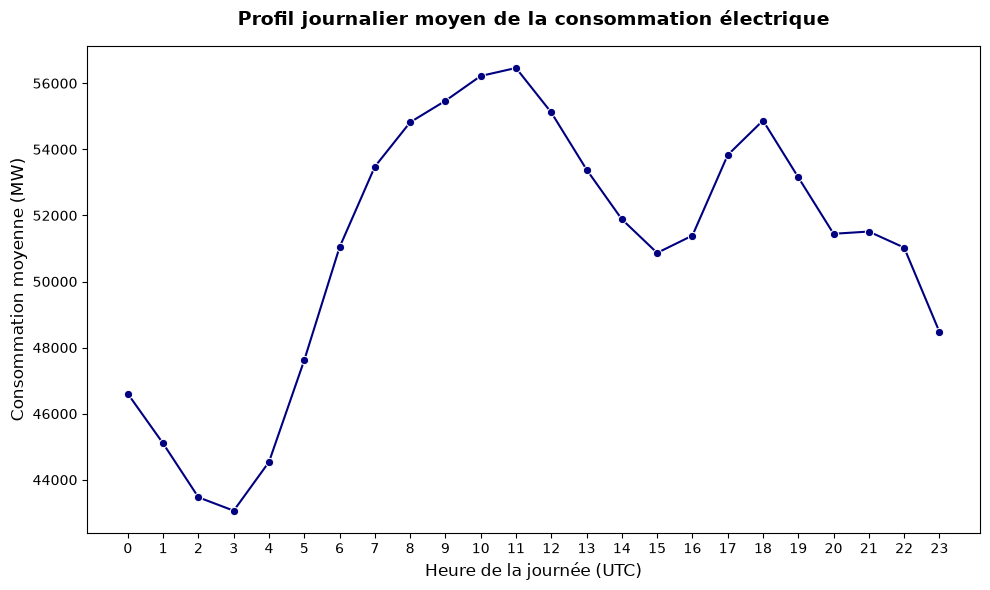

In [16]:
# Étape 1 : Calcul de la consommation moyenne pour chaque heure (de 0 à 23)
conso_moyenne_heure = df_rte_clean.groupby('Heure')['consommation'].mean()

# Étape 2 : Création du graphique avec matplotlib et seaborn
plt.figure(figsize=(10, 6))
sns.lineplot(x=conso_moyenne_heure.index, y=conso_moyenne_heure.values, marker="o", color="navy")

# Étape 3 : Personnalisation esthétique et clarté (critère d'évaluation)
plt.title("Profil journalier moyen de la consommation électrique", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Heure de la journée (UTC)", fontsize=12)
plt.ylabel("Consommation moyenne (MW)", fontsize=12)
plt.xticks(range(0, 24)) # Force l'affichage de chaque heure sur l'axe des abscisses

# Affichage du résultat
plt.tight_layout()
plt.show()

Ce graphique met en évidence la forte saisonnalité durant une journée pour la demande d'électricité. On observe 3 phases distinctes :

1. Le creux nocturne : La consommation atteint son minimum autour de 4h du matin, ainsi lorsque l'activité est au plus bas

2. Le pic de midi : La demande augmente fortement avec le réveil avec ensuite le début de l'activité industrielle et ou tertiaire. On observe alors un premier pic vers 12h.

3. Le pic du soir : Après le pic du midi, on observe une baisse durant l'après-midi. Par la suite on observe un second pic marqué à 19h. Cela correspond au retour des ménages dans leur foyer (Chauffage, Éclairage, Appareils électroménagers).

(L'heure étant en UTC, il ne faut pas oublier que pour trouver l'heure française il faut rajouter respectivement 1h en hiver et 2h en été)

## Analyse saisonnière
La France étant fortement équipée en chauffage électrique, la demande énergétique est très sensible aux variations de température. On va alors observer la consommaiton moyenne mensuelle.

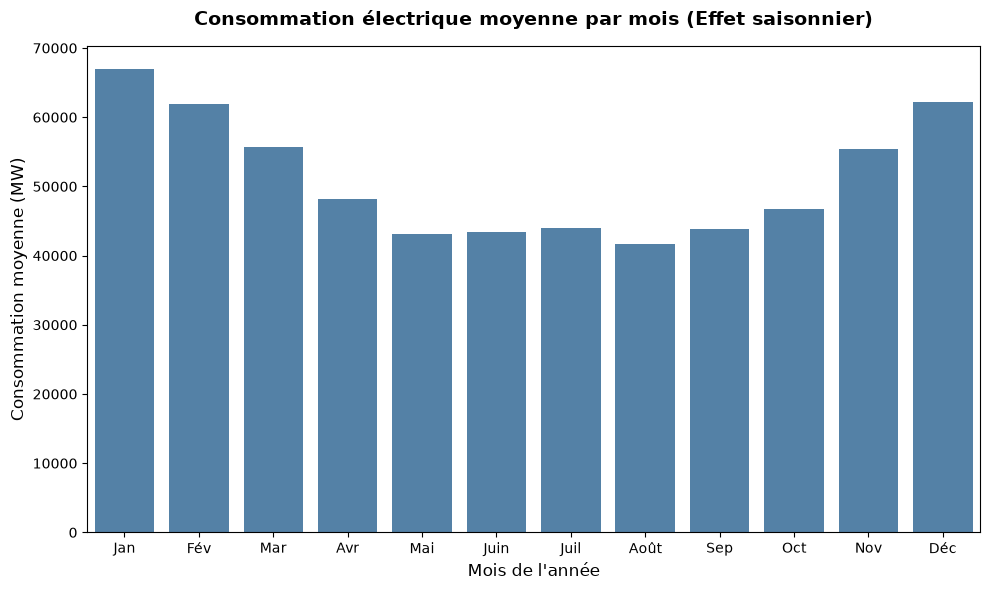

In [26]:
# Étape 1 : Calcul de la consommation moyenne pour chaque mois (de 1 à 12)
conso_moyenne_mois = df_rte_clean.groupby('Mois')['consommation'].mean()

# Étape 2 : Création du graphique en barres
plt.figure(figsize=(10, 6))
# On utilise seaborn pour un rendu propre, la couleur 'steelblue' reste sobre et académique
sns.barplot(x=conso_moyenne_mois.index, y=conso_moyenne_mois.values, color="steelblue")

# Étape 3 : Personnalisation (Titres, labels et remplacement des numéros par le nom des mois)
plt.title("Consommation électrique moyenne par mois (Effet saisonnier)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Mois de l'année", fontsize=12)
plt.ylabel("Consommation moyenne (MW)", fontsize=12)

mois_labels = ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin', 'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc']
plt.xticks(ticks=range(12), labels=mois_labels)

plt.tight_layout()
plt.show()

## Interprétation de la saisonnalité 
Le graphique confirme une forte thermosensibilité de la consommation électrique française. On y observe un pic hivernal (Décembre, Janvier, Févrrier) et un creux estival (Mai, Juin, Juillet, Août, Septembre). 

## Dynamique des énergies renouvelables

Pour comprendre les déséquilibres du réseau, il faut croiser la demande avec la production fatale (qu'on ne peut pas piloter). Regardons précisément la saisonnalité pour l'éolien et le solaire.

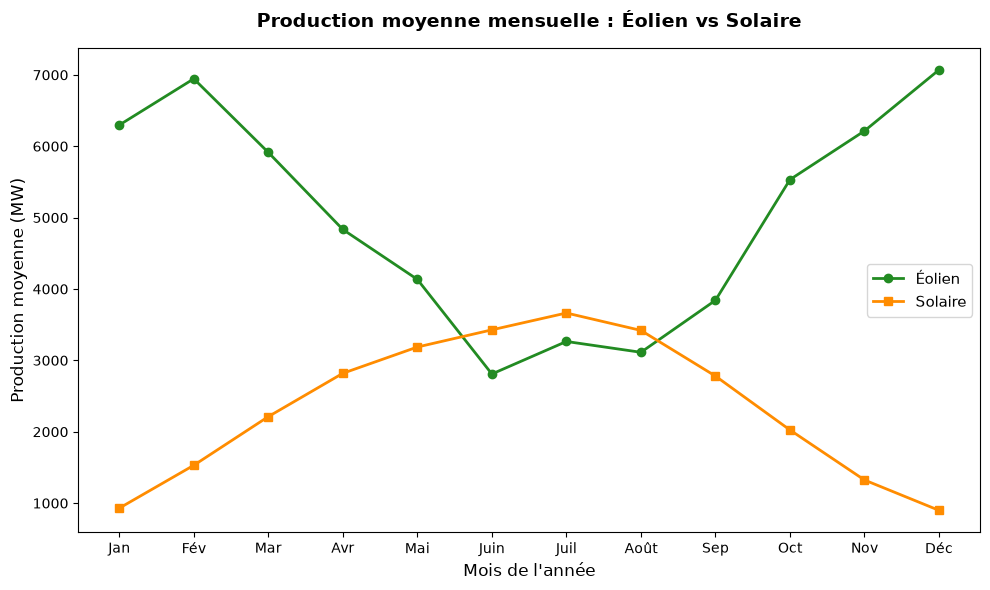

In [18]:
# Étape 1 : Calcul de la production moyenne pour chaque mois
prod_renouvelable_mois = df_rte_clean.groupby('Mois')[['eolien', 'solaire']].mean()

# Étape 2 : Création du graphique avec deux courbes superposées
plt.figure(figsize=(10, 6))

# Tracé de l'éolien (en vert) et du solaire (en orange)
plt.plot(prod_renouvelable_mois.index, prod_renouvelable_mois['eolien'], marker='o', label='Éolien', color='forestgreen', linewidth=2)
plt.plot(prod_renouvelable_mois.index, prod_renouvelable_mois['solaire'], marker='s', label='Solaire', color='darkorange', linewidth=2)

# Étape 3 : Personnalisation
plt.title("Production moyenne mensuelle : Éolien vs Solaire", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Mois de l'année", fontsize=12)
plt.ylabel("Production moyenne (MW)", fontsize=12)

# Reprise des mêmes labels pour garder la cohérence avec le graphique précédent
mois_labels = ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin', 'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc']
plt.xticks(ticks=range(1, 13), labels=mois_labels)

plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

## Inteprétation

Les deux sources d'énergies renouvelables présentent deux profils saisonniers opposés :
1. Le solaire suite logiquement une courbe en cloche inversée par rapport à la consommation, avec un pic de production en été car c'est là où on trouve un ensoleillement maximal.

2. L'éolien est beaucoup plus fort en hiver en raison des dépressions météorologiques plus fréquentes, ce qui coïncide avec la demande hivernale.

## Analyse de la charge résiduelle et risque de surproduction

La charge résiduelle est un indicateur clé de l'équilibre du réseau électrique. Une charge résiduelle très faible indique que la production renouvelable couvre presque ou totalement la demande du pays. Le système se retrouve alors en situation de surproduction physique, ce qui contraint la France à exporter massivement son excédent d'électricité vers ses voisins.

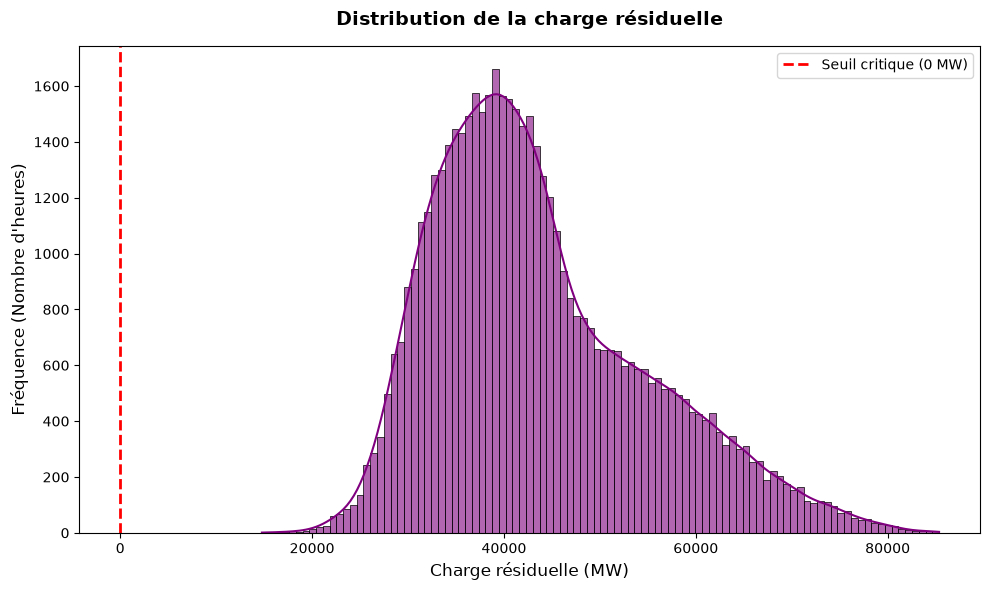

In [27]:
# Création de la figure
plt.figure(figsize=(10, 6))

# Tracé de l'histogramme avec une courbe de densité (KDE)
sns.histplot(df_rte_clean['charge_residuelle_mw'], bins=100, kde=True, color='purple', alpha=0.6)

# Ajout d'une ligne verticale rouge critique pour marquer le seuil de 0 MW
plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Seuil critique (0 MW)')

# Personnalisation
plt.title("Distribution de la charge résiduelle", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Charge résiduelle (MW)", fontsize=12)
plt.ylabel("Fréquence (Nombre d'heures)", fontsize=12)
plt.legend()

plt.tight_layout()
plt.show()

## Interprétation 

Cet histogramme permet de repérer la zone de tension pour le réseau. La majorité du temps, la charge résiduelle est largement positive. La queue de distribution à gauche montre les moments où cette charge s'approche de zéro : c'est dans ces épisodes que le réseau fait face à un risque de surproduction physique. 

Ici, on observe clairement dans le jeu de données que la charge résiduelle ne descend jamais en dessous de 15 000 MW. Cela s'explique par le fait qu'en France, la production éolienne et solaire cumulée n'est pas encore suffisante pour dépasser à elle seule la consommation nationale. 

Les situations d'exportations massives (traduisant un excédent de production) ne surviennent donc pas parce que la charge résiduelle est mathématiquement négative, mais lorsqu'elle devient très basse et que la production de base (comme le nucléaire) est complexe ou trop lente à baisser pour s'adapter instantanément.

## Identification des épisodes de tension 

On va ainsi isoler les 15 heures les plus critiques pour la charge résiduelle.

In [20]:
# On utilise la méthode 'nsmallest' de Pandas pour trouver les 15 valeurs les plus basses
episodes_critiques = df_rte_clean.nsmallest(15, 'charge_residuelle_mw')

# On sélectionne uniquement les colonnes pertinentes pour ne pas surcharger l'affichage
colonnes_a_voir = ['consommation', 'eolien', 'solaire', 'charge_residuelle_mw', 'Jour_semaine', 'Mois']

print("--- Les 15 des moments avec la plus faible charge résiduelle ---")
display(episodes_critiques[colonnes_a_voir])

--- Les 15 des moments avec la plus faible charge résiduelle ---


,consommation,eolien,solaire,charge_residuelle_mw,Jour_semaine,Mois
date_heure_utc,,,,,,
2023-08-06 14:00:00+00:00,36176.5,11885.5,9521.5,14769.5,6,8
2023-08-06 13:00:00+00:00,37410.5,11898.5,10337.0,15175.0,6,8
2023-08-06 12:00:00+00:00,38887.0,11862.5,10667.0,16357.5,6,8
2023-08-06 15:00:00+00:00,35803.0,11263.5,8017.5,16522.0,6,8
2023-08-05 14:00:00+00:00,39130.0,14327.0,7997.0,16806.0,5,8
2023-08-06 02:00:00+00:00,30392.0,13433.5,0.0,16958.5,6,8
2023-08-06 03:00:00+00:00,30051.0,13061.0,0.0,16990.0,6,8
2023-08-06 04:00:00+00:00,30133.0,12752.5,0.5,17380.0,6,8
2023-08-05 15:00:00+00:00,38723.5,14827.0,6343.0,17553.5,5,8


## Analyse des extrêmes 

En observant le tableau ci-dessus, on remarque que les moments de plus faible charge résiduelle partagent des caractéristiques communes : Jour_semaine = 5 ou 6 Mois = 8 ce qui correspond aux jours du week-end d'Août lorsque la consommation industrielle est faible mais que la production renouvelable est importante.

## Conclusion de l'exploration du système électrique
L'analyse des données de RTE met en lumière les dynamiques fondamentales de l'équilibre offre-demande en France et permet d'identifier physiquement les périodes de tension du réseau :

* **Thermosensibilité de la demande :** La consommation présente une forte saisonnalité annuelle (pic hivernal lié au chauffage) et un profil intra-journalier très marqué par l'activité humaine (creux nocturne, pics à 12h et 19h).

* **Complémentarité des énergies fatales :** L'éolien et le solaire s'équilibrent à l'échelle annuelle. La forte production éolienne hivernale coïncide de manière opportune avec la hausse de la demande nationale.

* **Risque de surproduction et charge résiduelle :** L'étude de la charge résiduelle démontre que les déséquilibres critiques n'apparaissent pas uniquement lors des pics de froid, mais surtout lors des week-ends estivaux (notamment en août). La combinaison d'une faible demande industrielle et d'une forte production renouvelable fait drastiquement chuter la demande restante sur le parc nucléaire pilotable.

* **Les exportations comme indicateur de tension :** Lors de ces épisodes de très faible charge résiduelle, le réseau français entre en situation de surproduction physique. Pour éviter une surcharge et maintenir la fréquence d'équilibre, la France exporte massivement son excédent vers les pays voisins (pics négatifs sur la variable des échanges physiques). Sur le marché de gros de l'électricité, ces situations de surproduction et d'exportations contraintes constituent le moteur physique principal de l'effondrement ponctuel des prix.
